In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint
import pickle

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.14.6 (main, Jun 10 2026, 18:54:31) [GCC 15.2.0]


In [2]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    n = lfm.n_input
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'Значения коэффициентов классификатора:  #(abs(param) > {p_threshold}) = {s}')

## Спектры из 20-й серии

In [3]:
path = f"/home/intellimath/YD/repos/spectra/20"
options = {}
dd = {}
# widgets.load_spectra(path, dd, options)

In [4]:
dd = io.load_spectra(path, {"вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })

In [5]:
dd.align_bottom()
dd.crop(400, 1700)
# dd.scale_by_mean()

In [6]:
dd.drop_zeros_spectrum()
dd.drop_notfinite()
dd.drop_empty()
dd.isfinite()

In [7]:
dd.plot_spectra(fract=True)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__20_3_1…

In [8]:
dd.denoise_svd()

In [9]:
dd.robust_averaging()

In [10]:
# dd.despike(1.0)

In [11]:
# dd.scale_by_mean()

In [12]:
# dd.plot_spectra(fract=True)

In [13]:
# dd.select_baselines( tau2=1.0e4,     
#                       func=funcs.RStep(0.05, 0.002),
#                       # func2=funcs.RStep(0.001, 0.001),
#                       func2_e=inventory.relative_abs_max,
#                       # verbose=False,
# )

In [14]:
dd.isfinite
dd.drop_notfinite()
dd.drop_zeros_spectrum()

In [15]:
dd.scale_by_mean()

In [16]:
dd.filter()

In [17]:
# dd.plot_smoothed(func=funcs.RStep(0.01, 0.001), 
#                  # func2_e=inventory.relative_abs_max, 
#                  tau2=1.0, d=4)

In [18]:
# dd.plot_spectra()

In [19]:
# dd.select_baselines(tau2=1.0e0, #tau1=-0.001,
#                       func=funcs.RStep(0.01, 0.001),
#                       func2=funcs.SoftAbs_Sqrt(0.001).derivative_div_array,
#                       func2_e=inventory.relative_abs_max,
#                       # verbose=False,
#                       d=2,
# )

In [20]:
dd.subtract_baselines(tau2=1.0e3, #tau1=-1.0e-3,
                      func=funcs.RStep(0.01, 0.002),
                      func2_e=inventory.relative_abs_max,
                      verbose=False, n_jobs=8
                     )

SA_97__20_3_1_1_термический_20260622_super_SE__H2O(HPLC)_
SA_97__20_3_1_2_термический_20260622_super_SE__H2O(HPLC)_
SA_97__20_3_1_3_термический_20260622_super_SE__H2O(HPLC)_
SA_97__20_4_1_1_термический_20260625_super_SE__H2O(HPLC)_
SA_97__20_4_1_2_термический_20260625_super_SE__H2O(HPLC)_
SA_97__20_4_1_3_термический_20260625_super_SE__H2O(HPLC)_
SA_97__20_5_1_1_термический_20260629_super_SE__H2O(HPLC)_
SA_97__20_5_1_2_термический_20260629_super_SE__H2O(HPLC)_
SA_97__20_5_1_3_термический_20260629_super_SE__H2O(HPLC)_
SH_15__20_3_1_1_термический_20260622_super_SE__H2O(HPLC)_
SH_15__20_3_1_2_термический_20260622_super_SE__H2O(HPLC)_
SH_15__20_3_1_3_термический_20260622_super_SE__H2O(HPLC)_
SH_15__20_4_1_1_термический_20260625_super_SE__H2O(HPLC)_
SH_15__20_4_1_2_термический_20260625_super_SE__H2O(HPLC)_
SH_15__20_4_1_3_термический_20260625_super_SE__H2O(HPLC)_
SH_15__20_5_1_1_термический_20260629_super_SE__H2O(HPLC)_
SH_15__20_5_1_2_термический_20260629_super_SE__H2O(HPLC)_
SH_15__20_5_1_

In [21]:
dd.scale_by_mean()

In [22]:
dd.filter()

In [23]:
dd.plot_spectra(fract=True)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__20_3_1…

In [24]:
dd.save("/home/intellimath/work/spectra/20_termo", "rm_bl")

In [25]:
dd2 = dd

In [26]:
dd2 = spectra.SpectraCollection()
dd2.load("/home/intellimath/work/spectra/20_termo", "rm_bl")

In [27]:
dd2.plot_spectra(fract=True)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SH_15__20_3_1…

In [28]:
# dd2 = dd

In [28]:
dd_SA = dd2.subcollection_by_attr_value("вид_бактерий", "SA")
dd_SS = dd2.subcollection_by_attr_value("вид_бактерий", "SS")
dd_SH = dd2.subcollection_by_attr_value("вид_бактерий", "SH")

dd_SH.union()
dd_SS.union()
dd_SH.union()

Ys_SA = dd_SA.union_y()
Ys_SS = dd_SS.union_y()
Ys_SH = dd_SH.union_y()
Ys_SAH = np.vstack((Ys_SA, Ys_SH))
Ys = dd2.union_y()
print(len(Ys_SA), len(Ys_SS), len(Ys_SH))


173 166 172


## Все спектры SH

In [29]:
dd_SH.union("SH").plot_spectra()

interactive(children=(IntSlider(value=0, description='i', layout=Layout(width='50%'), max=171), FloatRangeSlid…

## Все спектры SS

In [30]:
dd_SS.union("SS").plot_spectra()

interactive(children=(IntSlider(value=0, description='i', layout=Layout(width='50%'), max=165), FloatRangeSlid…

## Все спектры SA

In [31]:
dd_SA.union("SA").plot_spectra()

interactive(children=(IntSlider(value=0, description='i', layout=Layout(width='50%'), max=172), FloatRangeSlid…

In [25]:
c, As, Ls = pca.find_loc_and_pc_l2_lq(Ys, 10, 2.0)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
# plt.legend()
plt.show()

plt.figure(figsize=(12,5))
for i,a in enumerate(As):
    plt.plot(a, label=str(i+1))
plt.minorticks_on()
plt.grid(lw=0.5, ls=':')
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.title("Собственные числа")
plt.plot(Ls, marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

NameError: name 'Ys' is not defined

### Проекции спектров на пары главных компонент

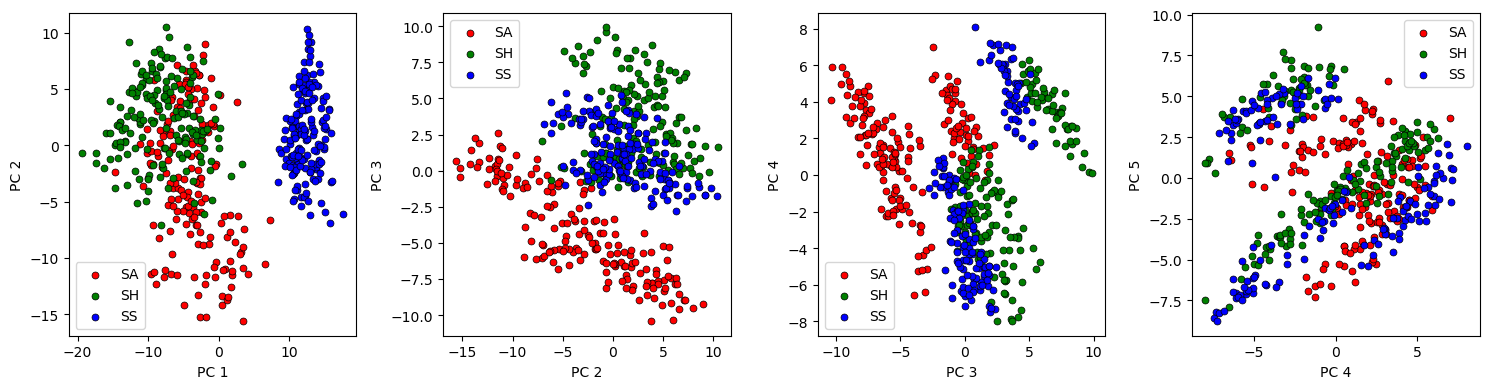

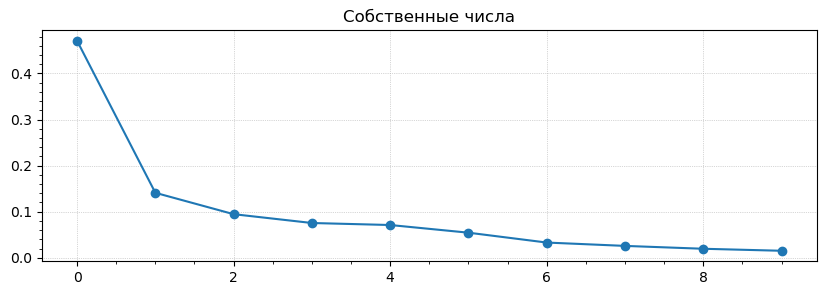

In [33]:
# c = np.zeros_like(Ys[0])
# As, Ls = pca.find_pc_all(Ys, 5)
c, As, Ls = pca.find_loc_and_pc(Ys, 10)
U = (Ys - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
# U_SAH = (Ys_SAH - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    # plt.scatter(U_SAH[:,i], U_SAH[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SAH")
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.title("Собственные числа")
plt.plot(Ls/Ls.sum(), marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

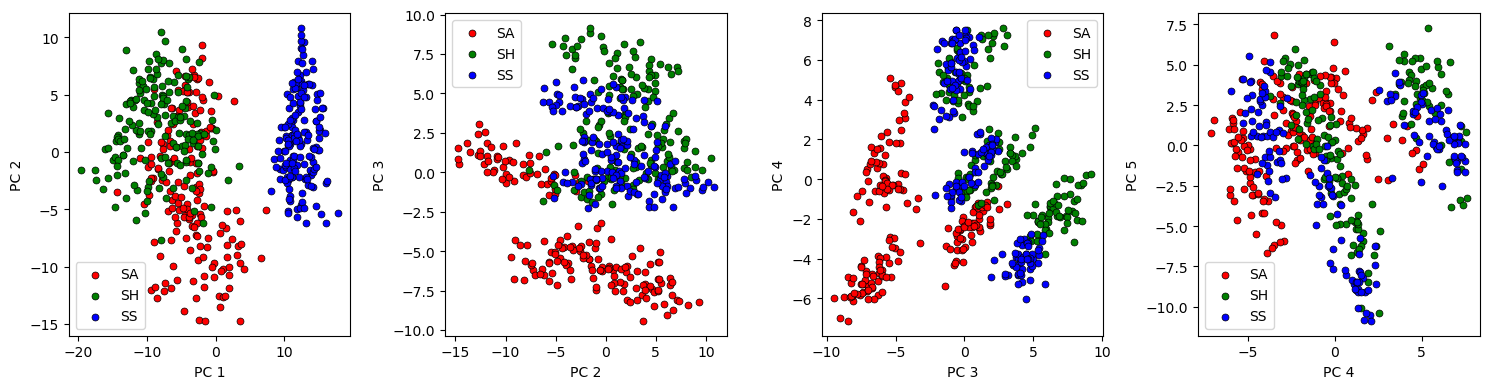

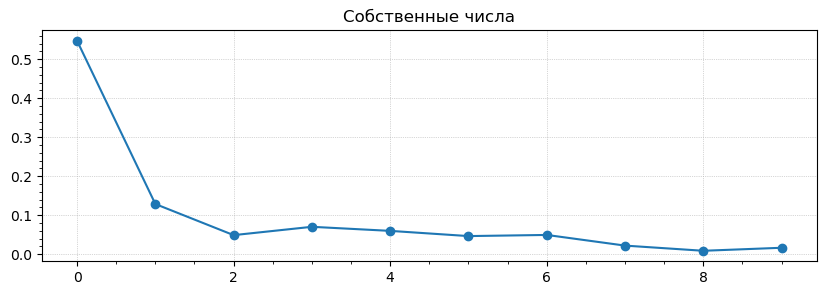

In [36]:
# c = np.zeros_like(Ys[0])
# As, Ls = pca.find_pc_all(Ys, 5)
wma = averaging_function("WMZ", kwds={"alpha":2.0})
c, As, Ls = pca.find_robust_loc_and_pc(Ys, wma, 10)
U = (Ys - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
# U_SAH = (Ys_SAH - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    # plt.scatter(U_SAH[:,i], U_SAH[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SAH")
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.title("Собственные числа")
plt.plot(Ls/Ls.sum(), marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

In [39]:
with open("pca_20_term2.pickle", mode="wb") as ff:
    pickle.dump([c, As, Ls, U_SA, U_SS, U_SH], ff)

In [40]:
# dd2.plot_spectra()

In [41]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

Zs_SS = np.ones(Ys_SS.shape[0])
Zs_SH = np.ones(Ys_SH.shape[0])
Zs_SA = np.ones(Ys_SA.shape[0])
Zs_SAH = np.ones(Ys_SAH.shape[0])

ys = np.concatenate((Ys_SS, Ys_SH, Ys_SA), axis=0)
zs = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA), axis=0)

ys0 = np.concatenate((Ys_SS,Ys_SAH), axis=0)
zs0 = np.concatenate((Zs_SS,-Zs_SAH), axis=0)
ys0 = np.ascontiguousarray(ys0)
zs0 = np.ascontiguousarray(zs0)

ys1 = np.concatenate((Ys_SS,Ys_SH), axis=0)
zs1 = np.concatenate((Zs_SS,-Zs_SH), axis=0)
ys1 = np.ascontiguousarray(ys1)
zs1 = np.ascontiguousarray(zs1)

ys2 = np.concatenate((Ys_SH,Ys_SA), axis=0)
zs2 = np.concatenate((Zs_SH,-Zs_SA), axis=0)
ys2 = np.ascontiguousarray(ys2)
zs2 = np.ascontiguousarray(zs2)

ys3 = np.concatenate((Ys_SA,Ys_SS), axis=0)
zs3 = np.concatenate((Zs_SA,-Zs_SS), axis=0)
ys3 = np.ascontiguousarray(ys3)
zs3 = np.ascontiguousarray(zs3)

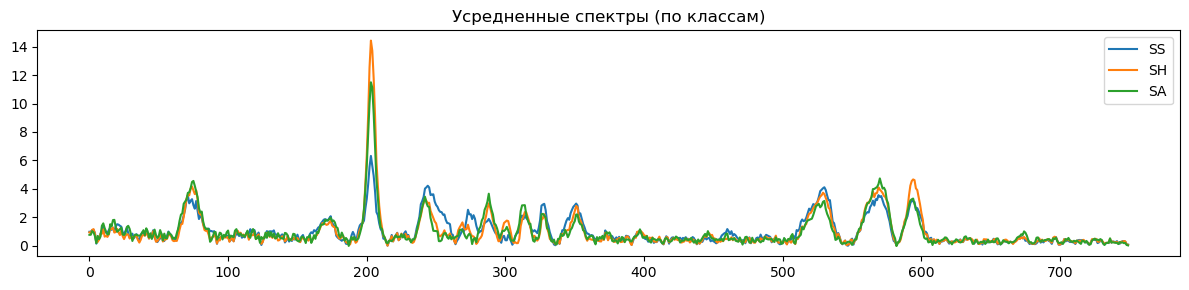

In [42]:
plt.figure(figsize=(12,3))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

## Модель 

В начале используется классификация по парам классов (SS/SH, SH/SA, SA/SS). 

Для классификации пары классов используется взвешенное голосование 
$$
y = \mathrm{sign}\left(\sum_{j=1}^M \alpha_j y_j\right)
$$
по $M=45$ сигмодиальным нейронам вида:
$$
y = \sigma\left(w_0+\sum_{i=1}^n w_i x_i\right),\quad \sigma(s)=\tanh(s)
$$ 
Веса $\alpha_j$ равны относительному числу правильных ответов для $j$-го сигмоидального нейрона на обучающей выборке.

In [43]:
import joblib
import sys

@joblib.delayed
def fit_snm(ys, zs, weights, tau=0, accuracy_min=0.75, n_try=5, sigma=1.0, p_threshold=1.0e-4):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(sigma), ys.shape[1])
    mod.allocate()
    mod.init_param()
    mod.use_regularizer(funcs2.AbsoluteNorm(), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = None

    for i in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.1)),
                              # loss_func=loss.ErrorLoss(funcs.Abs()),
                              # regnorm=funcs2.AbsoluteNorm(),
                              projector=projector, 
                              weights=weights,
                              h=0.005, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        # sys.stdout.write(f"{w} {(mod.ob_param > 0).sum()}, ")
        # sys.stdout.flush()
        if w >= accuracy_min:
            break
    # sys.stdout.write("\n")
    return mod, w

def fit_lfm(ys, zs, tau=0, *, n_model=45, accuracy_min=0.75, n_try=5, sigma=1.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    with joblib.Parallel(n_jobs=4, max_nbytes=None) as parallel:
        results = parallel(
            fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma)
            for i in range(n_model)
        )

    lfm = models.LinearFuncModel()
    for mod, w in results:
    # for i in range(n_model):
    #     mod, w = fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma, p_threshold=p_threshold)
        lfm.add(mod, w)

    inventory.normalize(lfm.weights.asarray())
    return lfm

#### SS/SAH

> Коэффициенты всех голосующих классификаторов отложены на одном рисунке

In [40]:
lfm0 = fit_lfm(ys0, zs0, tau=50.0)
print(accuracy_score(zs0, np.sign(lfm0.evaluate(ys0))))

1.0


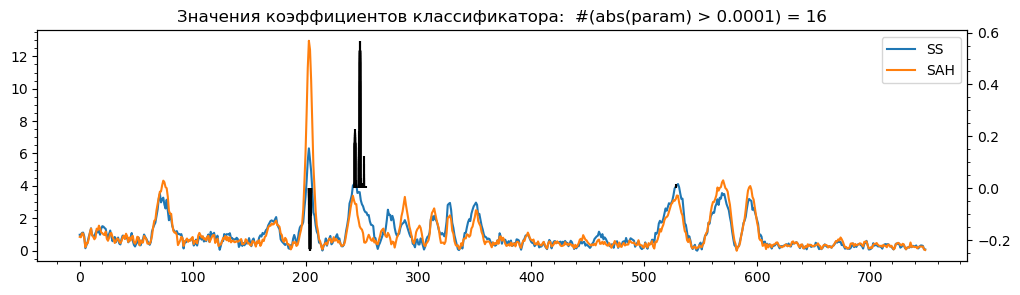

In [41]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SAH.mean(axis=0), label="SAH")
plt.minorticks_on()
plt.legend()
plot_params(lfm0)
plt.show()
# print(np.asarray(lfm0.models[0].param))

In [42]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm0, ys0, zs0)

In [43]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs0*lfm0.evaluate(ys0)))), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

#### SS/SH

In [44]:
lfm1 = fit_lfm(ys1, zs1, tau=50.0)
print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

1.0


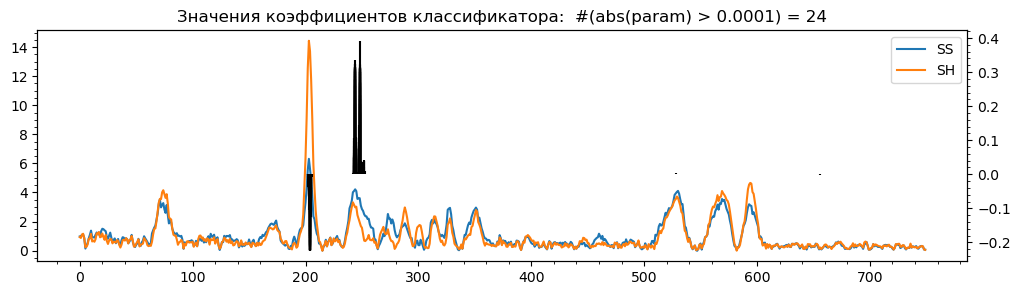

In [45]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_params(lfm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

In [46]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm1, ys1, zs1)

In [47]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

### SH SA

In [48]:
lfm2 = fit_lfm(ys2, zs2, tau=30.0)
print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

1.0


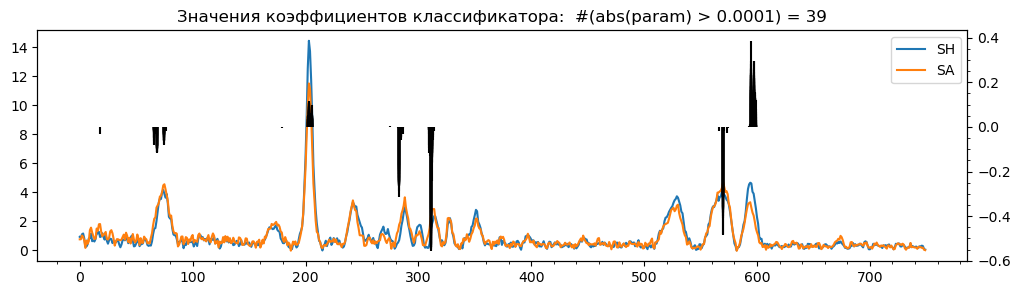

In [49]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plot_params(lfm2)
plt.show()

In [50]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm2, ys2, zs2)

In [51]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))), marker='o', ms=3)
# # plt.plot(sorted(zs2*lfm2.evaluate(ys2)), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

### SA SS

In [52]:
lfm3 = fit_lfm(ys3, zs3, tau=50.0)
print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

1.0


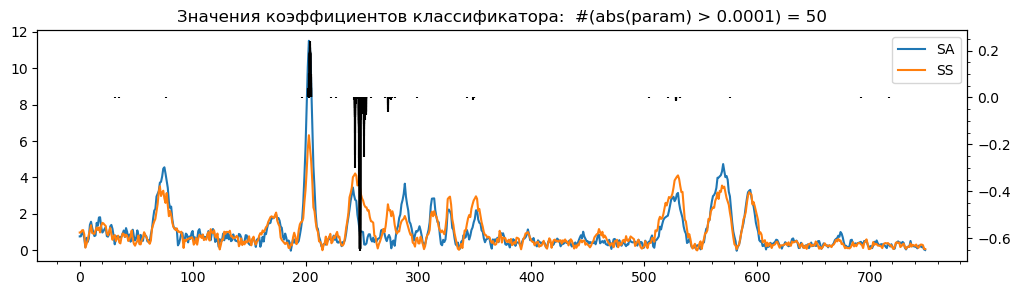

In [53]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.legend()
plot_params(lfm3)
plt.show()

In [54]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm3, ys3, zs3)

In [55]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

In [56]:
with open("lfm_20_term.pickle", "wb") as f:
    pickle.dump([lfm0, lfm1, lfm2, lfm3], f)

In [57]:
with open("lfm_20_term.pickle", "rb") as f:
    lfm0, lfm1, lfm2, lfm3 = pickle.load(f)


## Проекции обученных 3-х классификаторов на обучающей выборке: тернарная проекция на комплексной плоскости и проекция на декартову плоскость

511
166
172
1


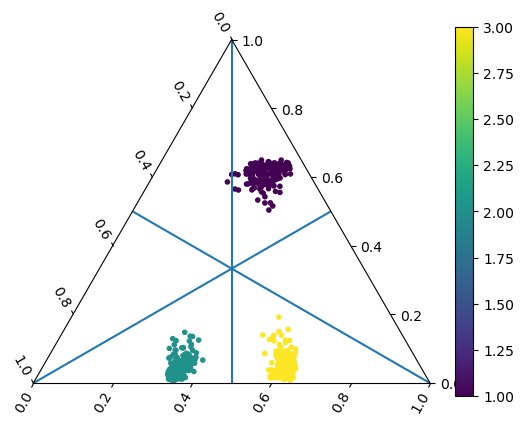

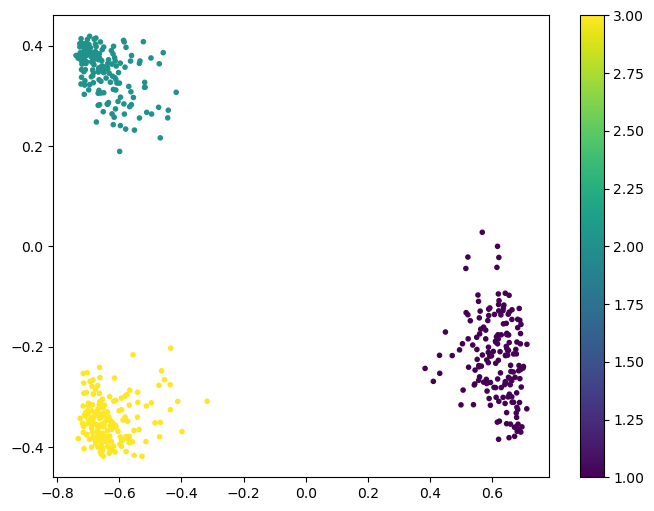

In [58]:
import mpltern
print(len(ys))

ax = plt.subplot(projection="ternary")
Z1 = lfm1.evaluate(ys)
Z2 = lfm2.evaluate(ys)
Z3 = lfm3.evaluate(ys)
Y1 = (1 + (Z1 - Z3) / 2) / 2
Y2 = (1 + (Z2 - Z1) / 2) / 2
Y3 = (1 + (Z3 - Z2) / 2) / 2
Y1[Y1<0] = 0
Y2[Y2<0] = 0
Y3[Y3<0] = 0
print(((Z1>0) & (Z3<0)).sum())
print(((Z2>0) & (Z1<0)).sum())
print(((Z2>0) & (Z3<0)).sum())
# print(Y1)
# print(Y2)
# print(Y3)
C = [(y1,y2,y3) for y1,y2,y3 in zip(Y1,Y2,Y3)]
# cax = ax.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax.transAxes)
cs = ax.scatter(Y1, Y2, Y3, c=zs, s=9)
plt.colorbar(cs)
ax.axline(
    [0.5, 0.0, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.5, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.0, 0.5],
    [0.5, 0.5, 0.5])
plt.show()

zz1 = Y1
zz2 = Y2 * np.exp(2j/3 * np.pi)
zz3 = Y3 * np.exp(-2j/3 * np.pi)
C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(8,6))
cs = plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=9, c=C)
plt.colorbar(cs)
plt.show()


In [59]:
from sklearn.linear_model import LogisticRegression

XX = np.c_[np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3)]
YY = np.concatenate((Zs_SS-1, Zs_SH, 2*Zs_SA))

lrg = LogisticRegression()
lrg.fit(XX, YY)
print(accuracy_score(YY, lrg.predict(XX)))

1.0


In [60]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
def plot_confusion_matrix(Y, Yp, labels): #, Y_test, Z, Z_test):
    cm = confusion_matrix(Y, Yp, normalize="true")
    plt.figure(figsize=(4,3))
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=labels, yticklabels=labels, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.show()


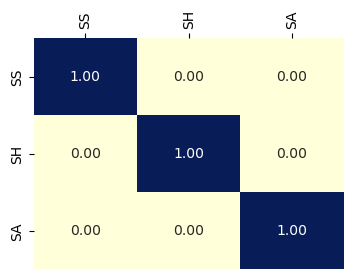

In [61]:
plot_confusion_matrix(YY, lrg.predict(XX), labels=["SS", "SH", "SA"])

# Спектры 22-й серии

In [3]:
path = f"/home/intellimath/YD/repos/spectra/22_SU"
dd_test = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [4]:
# import pandas as pd
# df = pd.read_csv("spectra_20_tab1.csv", sep="\t")
# cls_col = df["cls"]
# cls_name_col = cls_col.apply(lambda x: x.split("/")[0])
# cls_nn_col = cls_col.apply(lambda x: x.split("/")[1])
# df.__delitem__("cls")
# df["cls_name"] = cls_name_col
# df["cls_nn"] = cls_nn_col
# id1_array = df["id1"].values
# id2_array = df["id2"].values
# id_to_cls = {int(id):name.upper() for id,name in zip(id1_array, cls_name_col.values)}
# id_to_cls

In [5]:
# dd1 = spectra.SpectraCollection()
# for key in dd_test.spectra.keys():
#     keys = key.split("_")
#     id0 = keys[0]
#     id = int(id0[2:])
#     keys[1] = id0
#     keys[0] = id_to_cls[id].upper()
#     new_key = "_".join(keys)
#     sp = dd_test.spectra[key]
#     sp.attrs["key"] = new_key
#     sp.attrs["вид_бактерий"] = keys[0]
#     dd1[new_key] = sp
# dd_test = dd1
# del dd1

In [6]:
dd_test.align_bottom()
dd_test.crop(400,1700)
# dd_test.scale_by_mean()

In [7]:
dd_test.filter()

In [8]:
dd_test.drop_zeros_spectrum()
dd_test.drop_notfinite()
dd_test.drop_empty()
dd_test.isfinite()

In [9]:
# dd_test.despike(2.0)

In [10]:
# dd_test.denoise_svd()

In [11]:
dd_test.robust_averaging()

In [12]:
# dd_test.despike(2.0)

In [13]:
# dd_test.denoise_svd()

In [14]:
dd_test.isfinite
dd_test.drop_notfinite()
dd_test.drop_zeros_spectrum()

In [15]:
# dd.scale_by_mean()
# dd_test.scale_by_mean()

In [16]:
dd_test.filter()

In [17]:

# dd2_test.select_baselines(tau2=1.0e3, #tau1=-0.0001,
#                      func=funcs.RStep(0.0, 0.002), 
#                      func2_e=inventory.relative_abs_max,                     
#                     )

In [18]:
dd_test.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SU10___21_Tes…

In [19]:
dd_test.subtract_baselines(tau2=1.0e3, #tau1=-0.001,
                      func=funcs.RStep(0.01, 0.002),
                      func2_e=inventory.relative_abs_max,
                      verbose=False, n_jobs=8                           
                     )
dd_test.scale_by_mean()

SU10___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU11___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU12___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU13___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU14___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU15___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU16___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU17___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU18___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU19___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU1___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU20___21_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SU3___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU4___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU5___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU6___21_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SU7___21_Test__1_термический_20260703_super_S

In [20]:
dd_test.plot_spectra(fract=True)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SU10___21_Tes…

In [21]:
dd.plot_spectra(fract=True)

NameError: name 'dd' is not defined

In [23]:
# dd_SA_test = dd_test.subcollection_by_attr_value("вид_бактерий", "SA97")
# dd_SS_test = dd_test.subcollection_by_attr_value("вид_бактерий", "SS17")
# dd_SH_test = dd_test.subcollection_by_attr_value("вид_бактерий", "SH15")

# dd_SA_test.union()
# dd_SS_test.union()
# dd_SH_test.union()

# Ys_SA_test = dd_SA_test.union_y()
# Ys_SS_test = dd_SS_test.union_y()
# Ys_SH_test = dd_SH_test.union_y()
# Ys_SAH_test = np.vstack((Ys_SA_test, Ys_SH_test))
Ys_test = dd_test.union_y()
# print(len(Ys_SA_test), len(Ys_SS_test), len(Ys_SH_test))


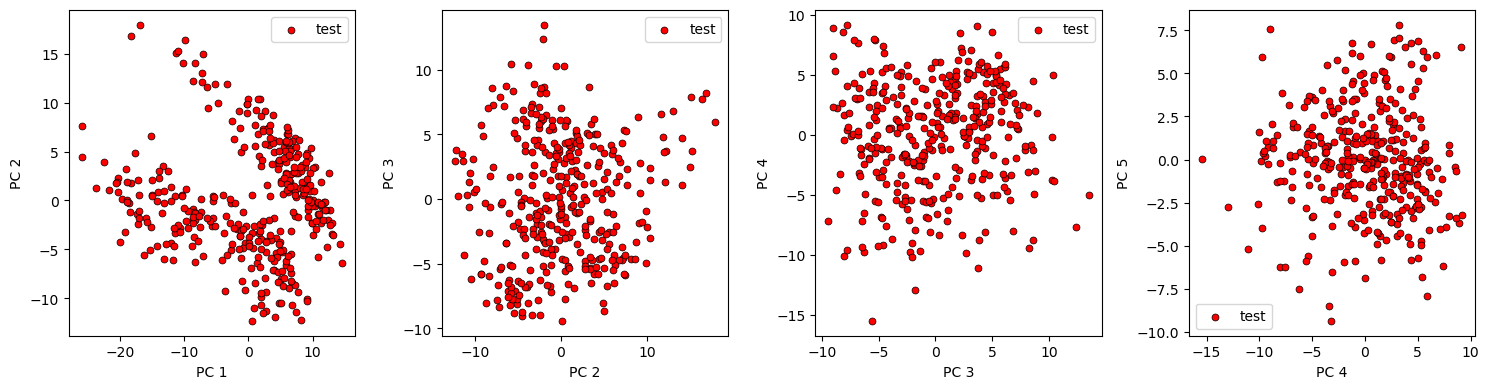

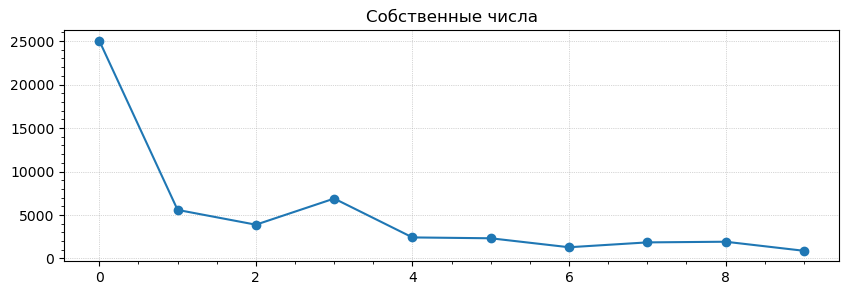

In [24]:
wma = averaging_function("WMZ", kwds={"alpha":3.5})
c_test, As_test, Ls_test = pca.find_robust_loc_and_pc(Ys_test, wma, 10)
U_test = (Ys_test - c_test) @ As_test.T
# U_SS = (Ys_SS - c) @ As.T
# U_SAH = (Ys_SAH - c) @ As.T
# U_SA = (Ys_SA - c) @ As.T
# U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_test[:,i], U_test[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="test")
    # plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    # plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    # plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.title("Собственные числа")
plt.plot(Ls_test, marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

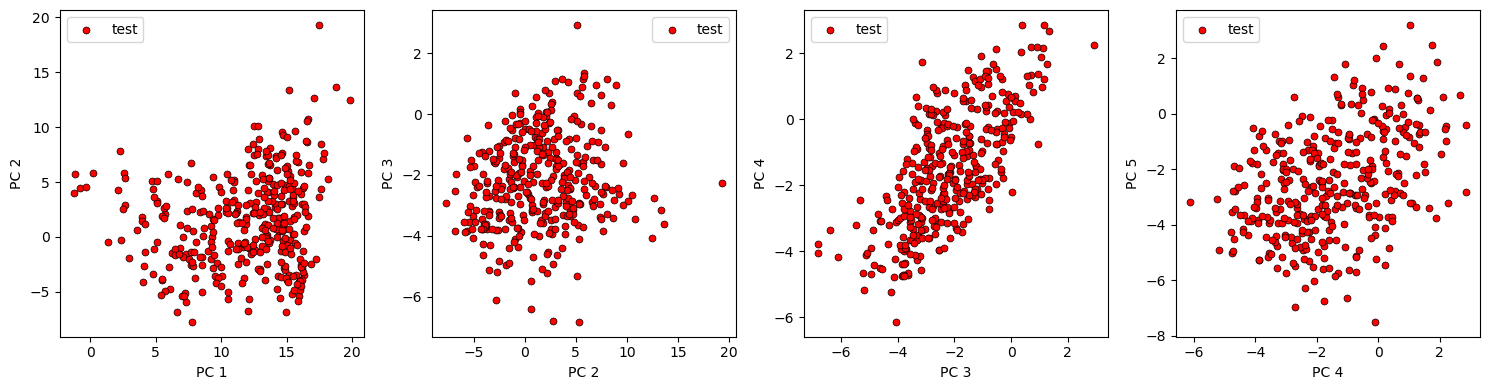

In [70]:
UU_test = (Ys_test - c) @ As.T
# U_SS = (Ys_SS - c) @ As.T
# U_SAH = (Ys_SAH - c) @ As.T
# U_SA = (Ys_SA - c) @ As.T
# U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(UU_test[:,i], UU_test[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="test")
    # plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    # plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    # plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()


In [81]:
# plt.figure(figsize=(12,3))
# plt.title("Усредненные спектры (по классам)")
# plt.plot(Ys_SS_test.mean(axis=0), label="SS")
# plt.plot(Ys_SH_test.mean(axis=0), label="SH")
# plt.plot(Ys_SA_test.mean(axis=0), label="SA")
# plt.legend()
# plt.tight_layout()
# plt.show()

In [82]:
keys = list(dd_test.keys())
@ipywidgets.interact(key=keys)
def plot_pca(key):
    sp = dd_test.spectra[key]
    Ys_test = sp.y
    U_test = (Ys_test - c) @ As.T
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.scatter(U_SS[:,0], U_SS[:,1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U_SA[:,0], U_SA[:,1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,0], U_SH[:,1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_test[:,0], U_test[:,1], s=64, c='m', edgecolors='k', linewidth=0.5, label=f"Test ({sp.key[:4]})")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
    plt.subplot(1,2,2)
    plt.scatter(U_SS[:,1], U_SS[:,2], s=25, c='r', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U_SA[:,1], U_SA[:,2], s=25, c='b', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,1], U_SH[:,2], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_test[:,0], U_test[:,1], s=64, c='m', edgecolors='k', linewidth=0.5, label=f"Test ({sp.key[:4]})")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    

interactive(children=(Dropdown(description='key', options=('SU10___21_Test__1_термический_20260703_super_SE__H…

## Проекции тестовых классов на на главные компоненты, найденные по обучающей выборке

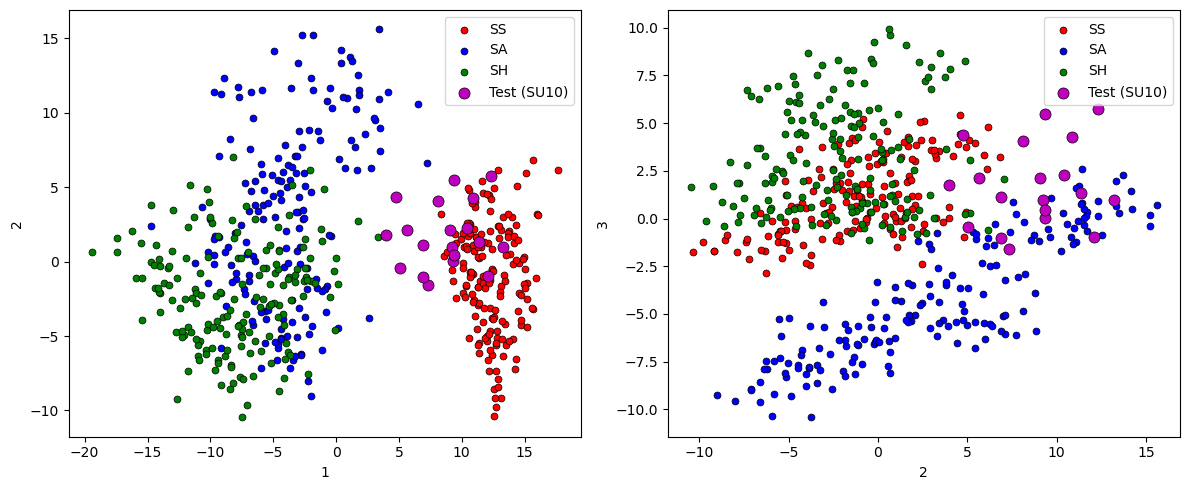

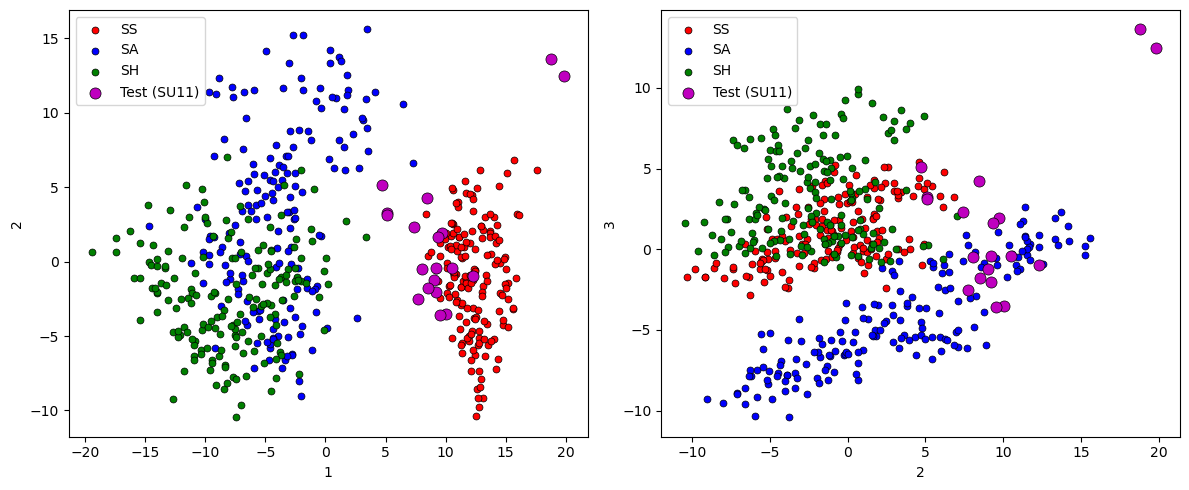

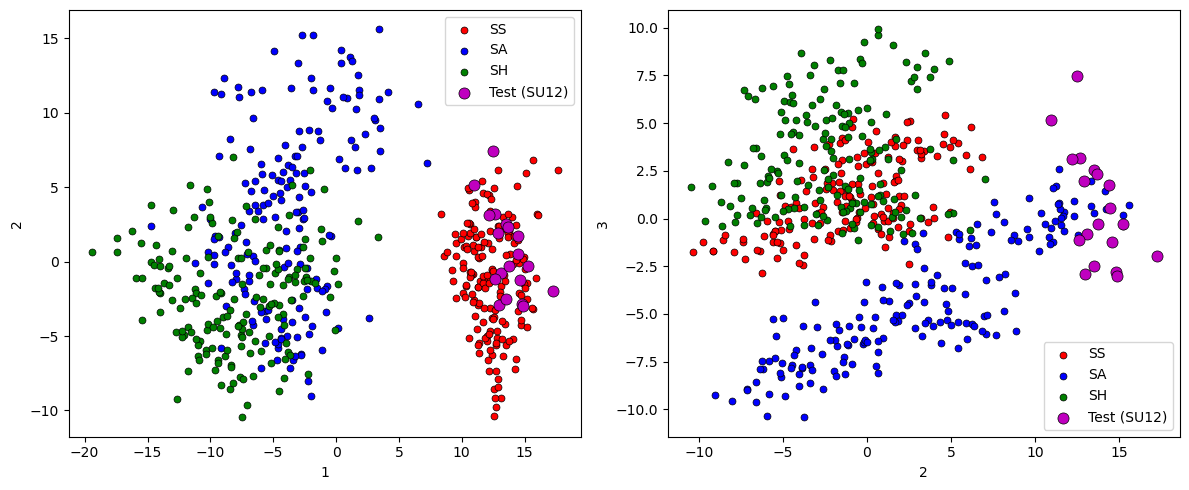

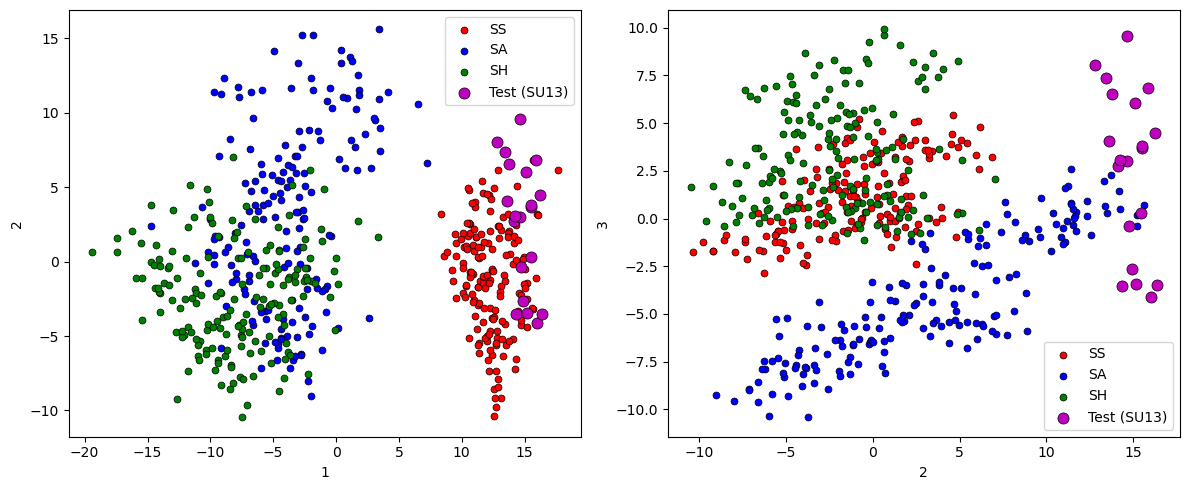

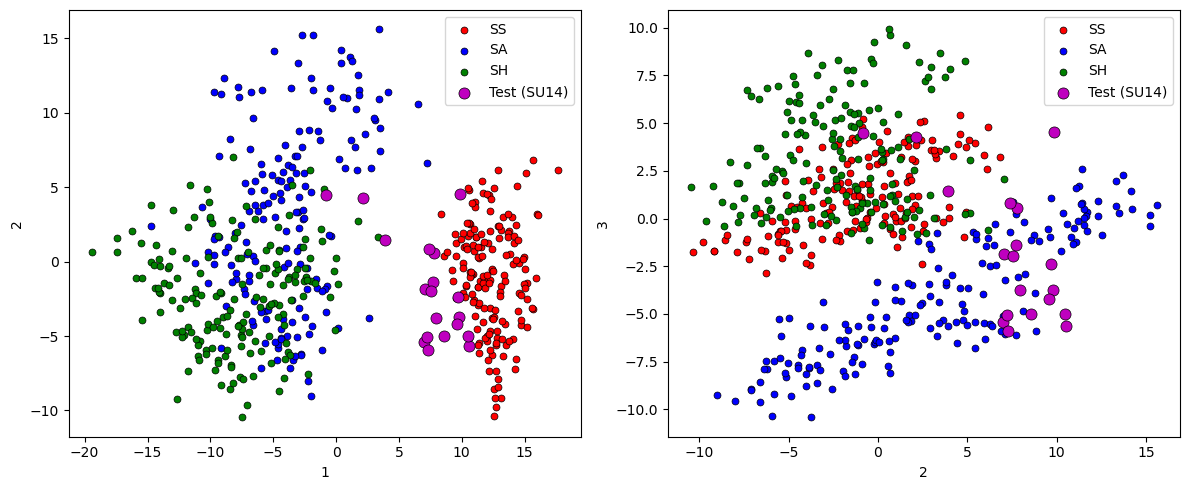

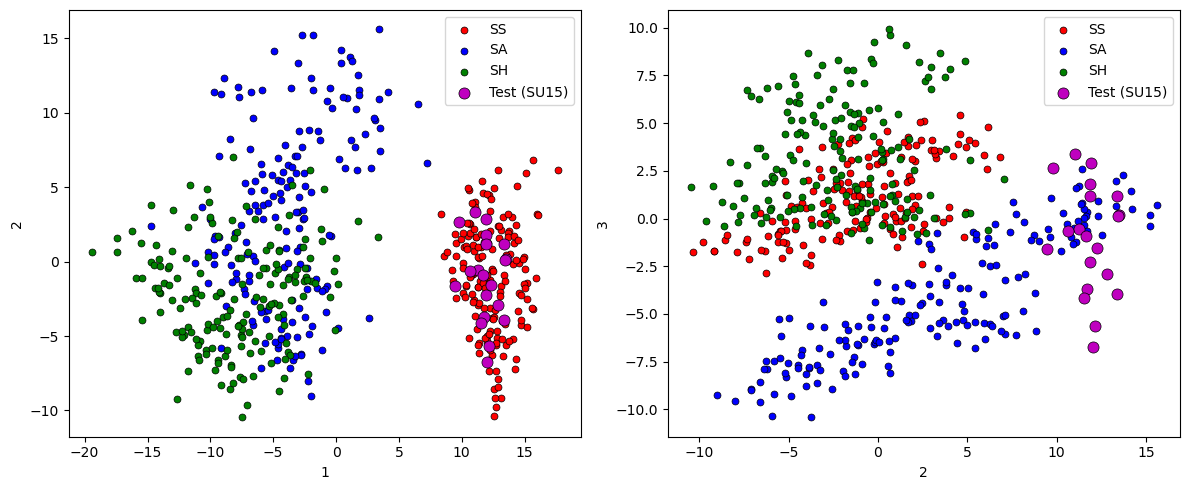

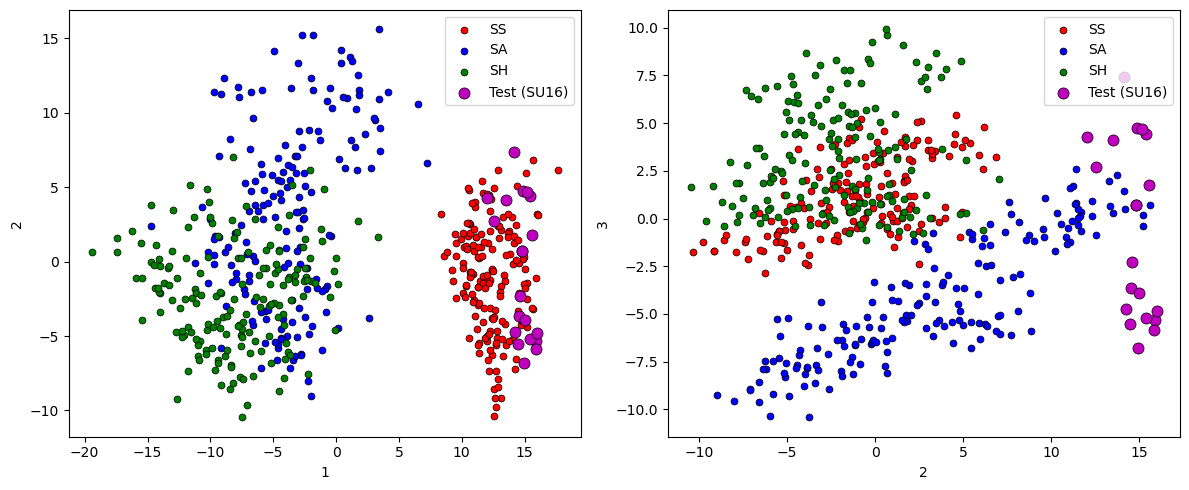

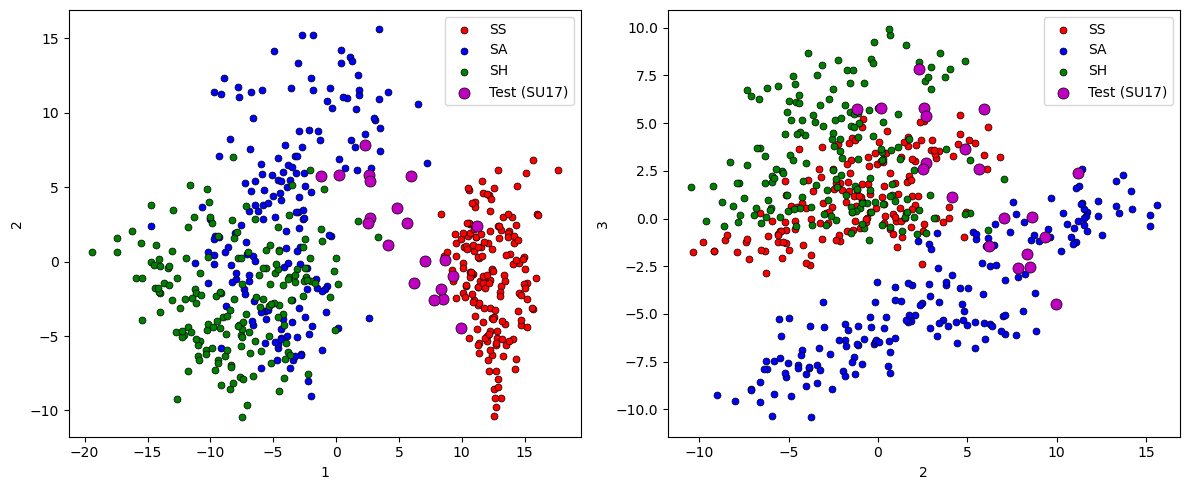

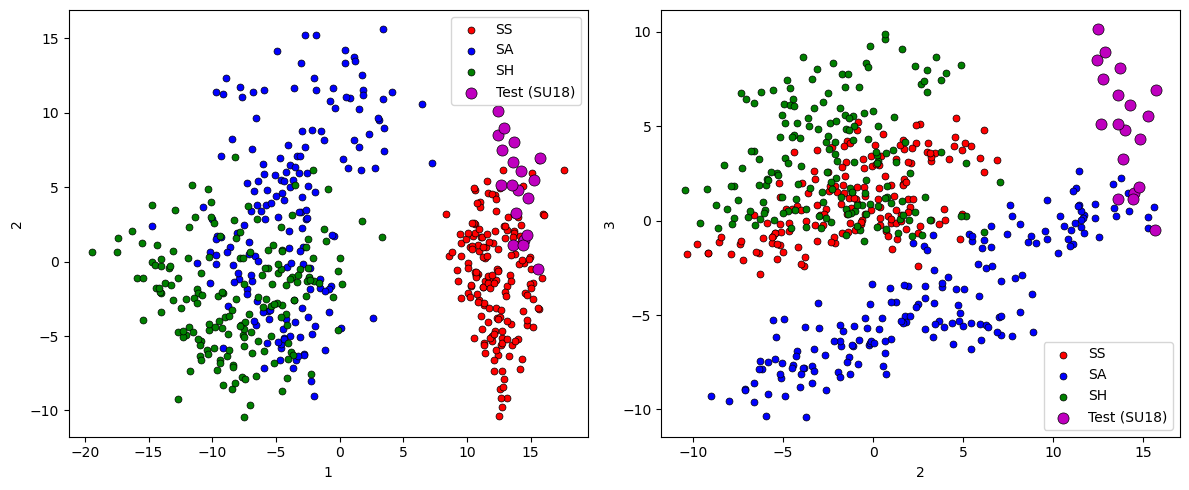

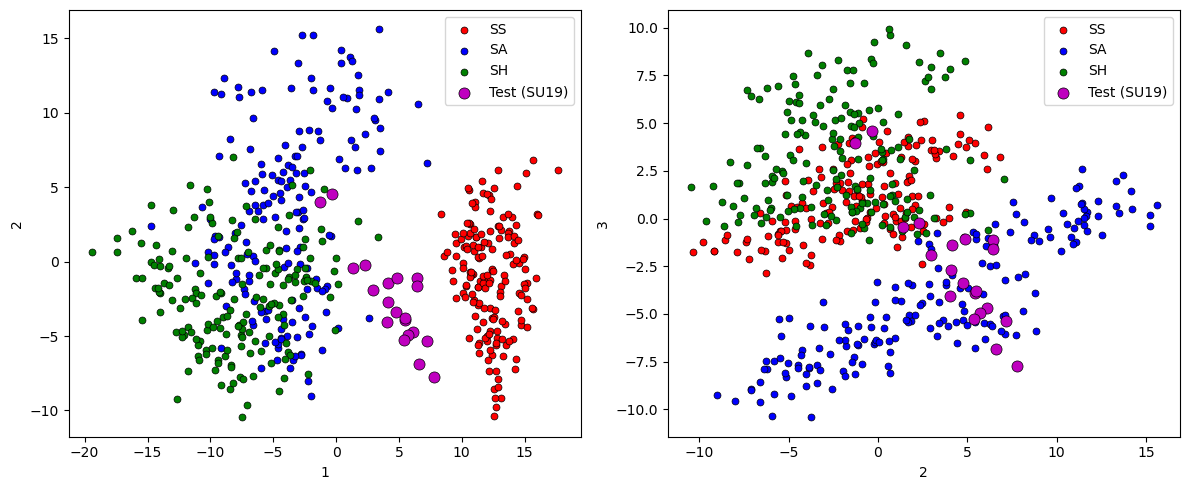

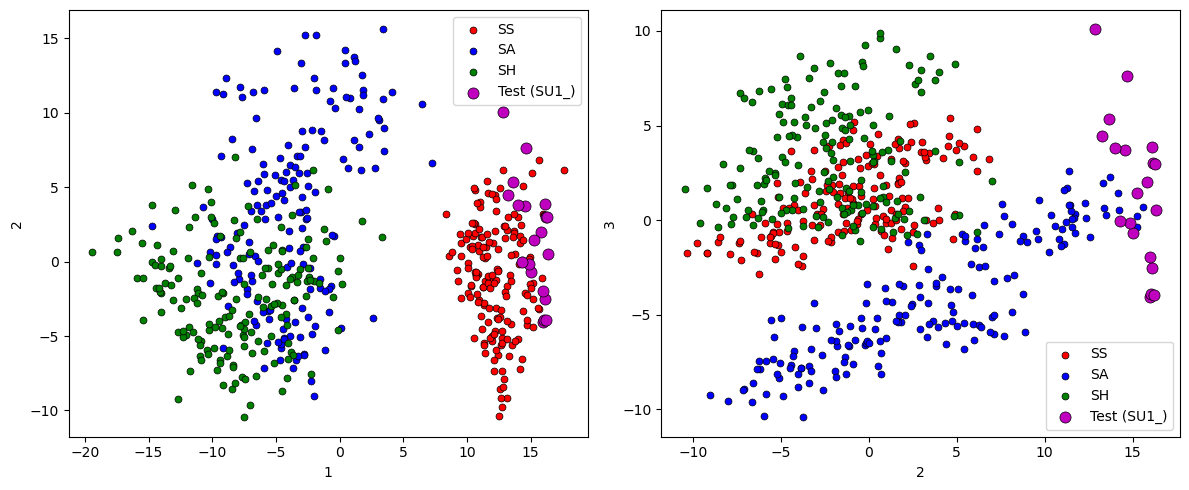

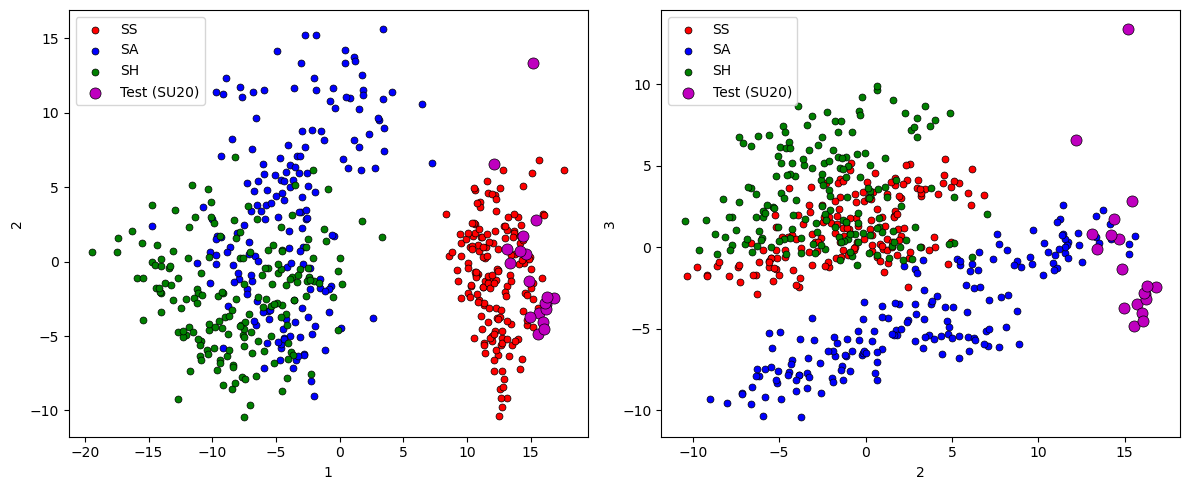

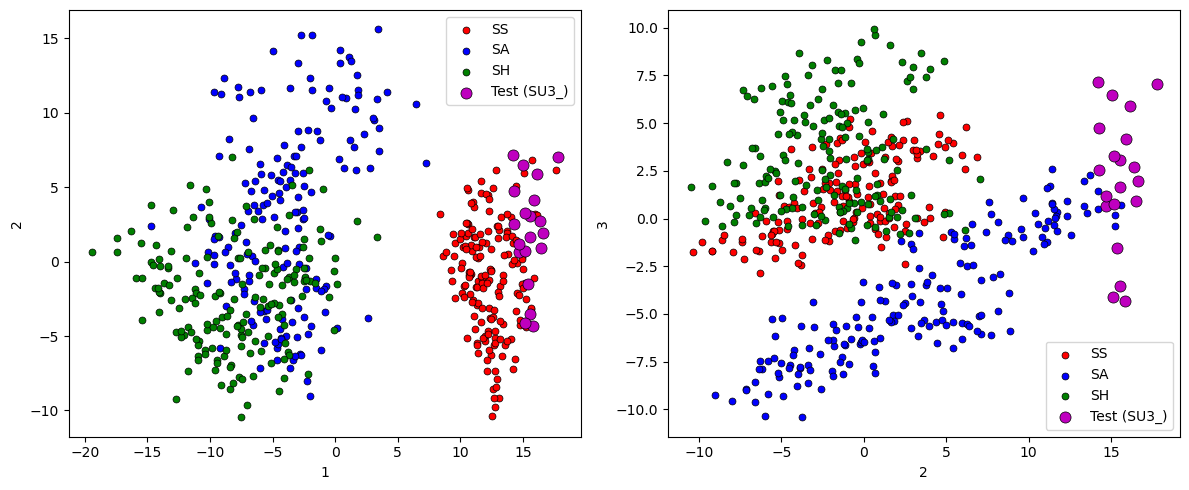

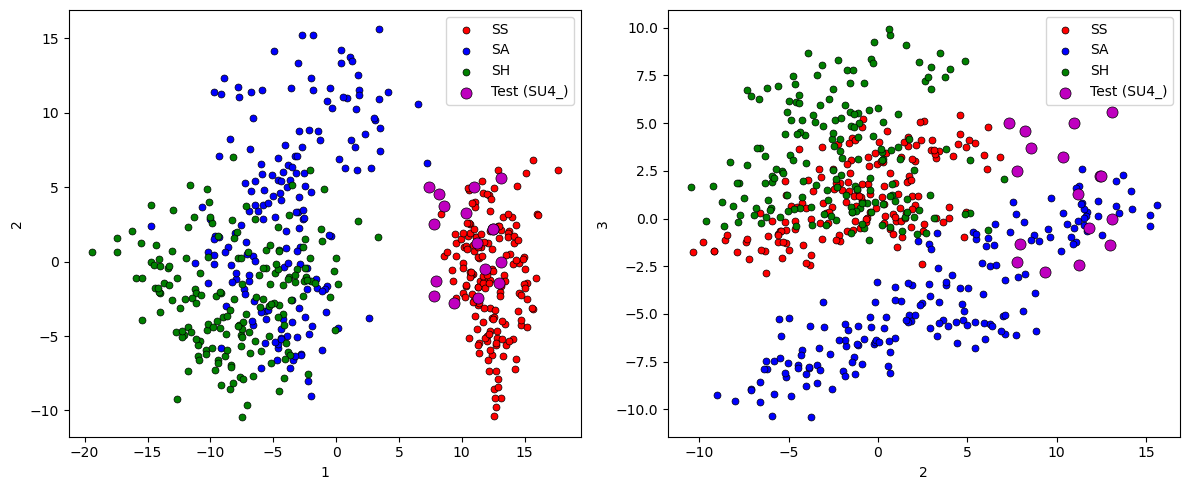

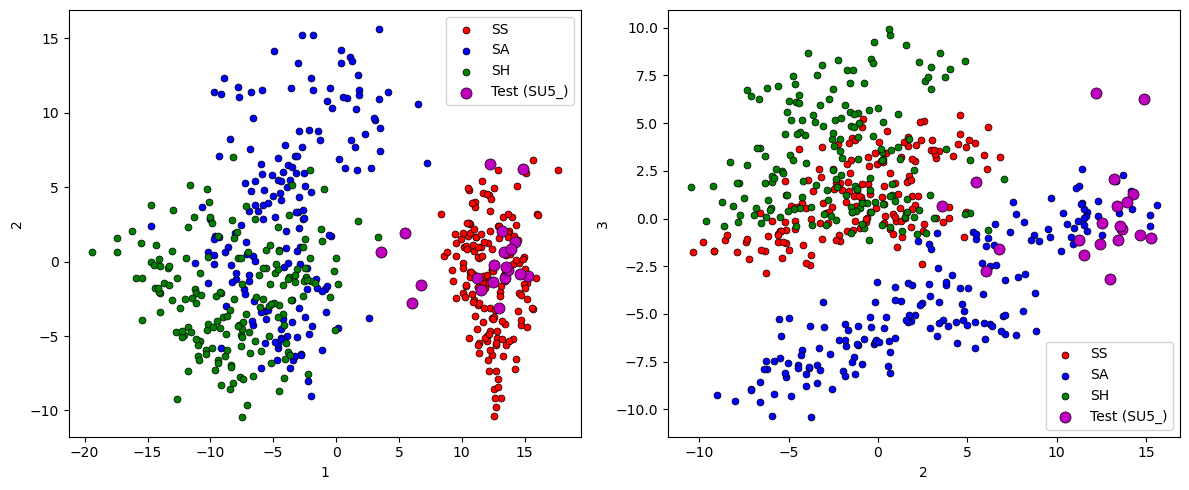

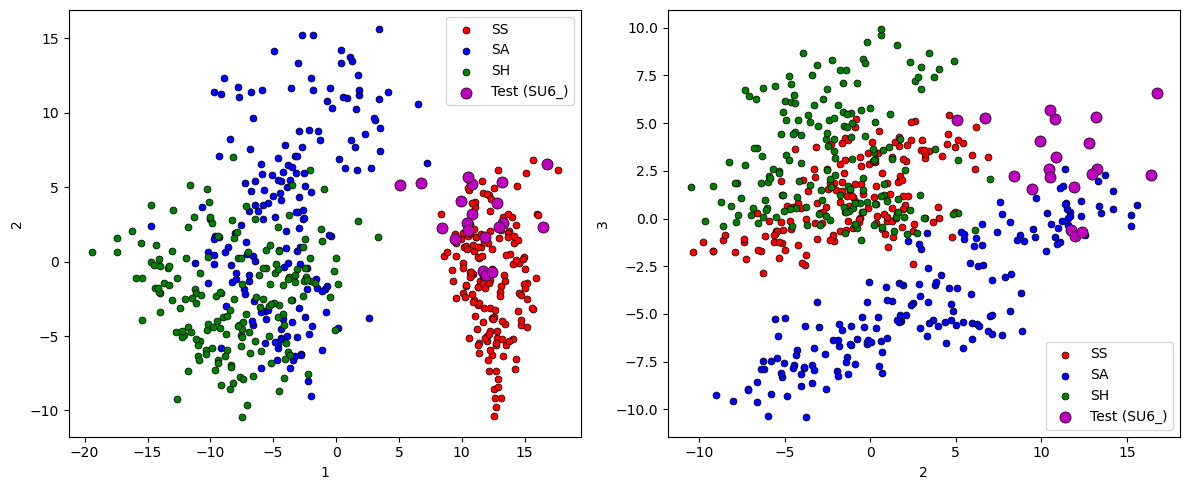

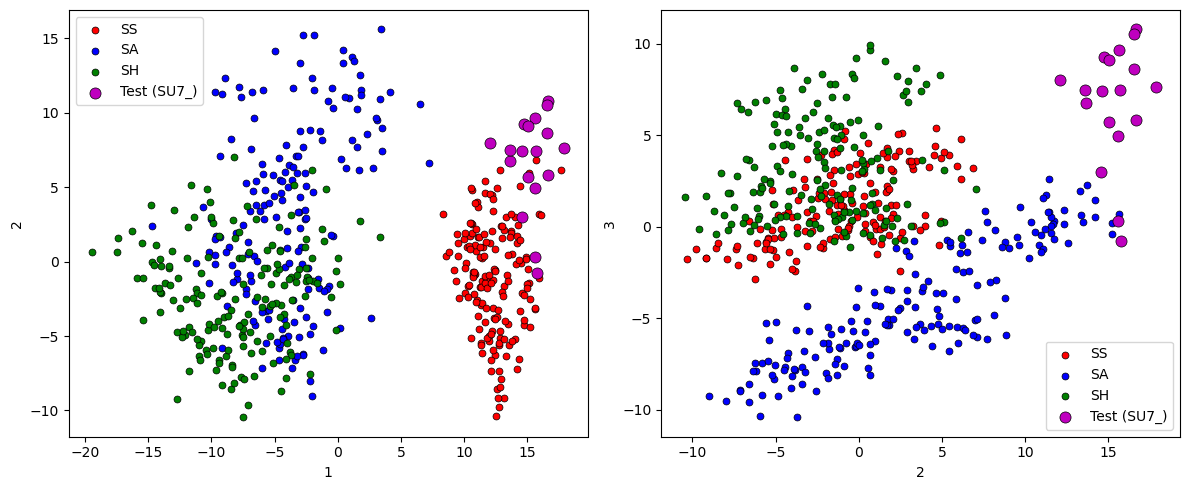

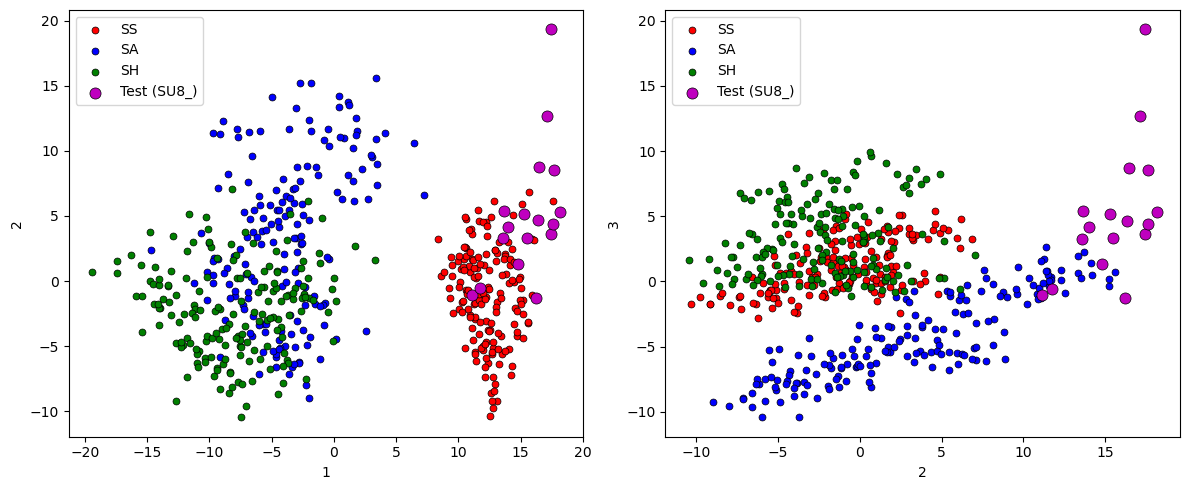

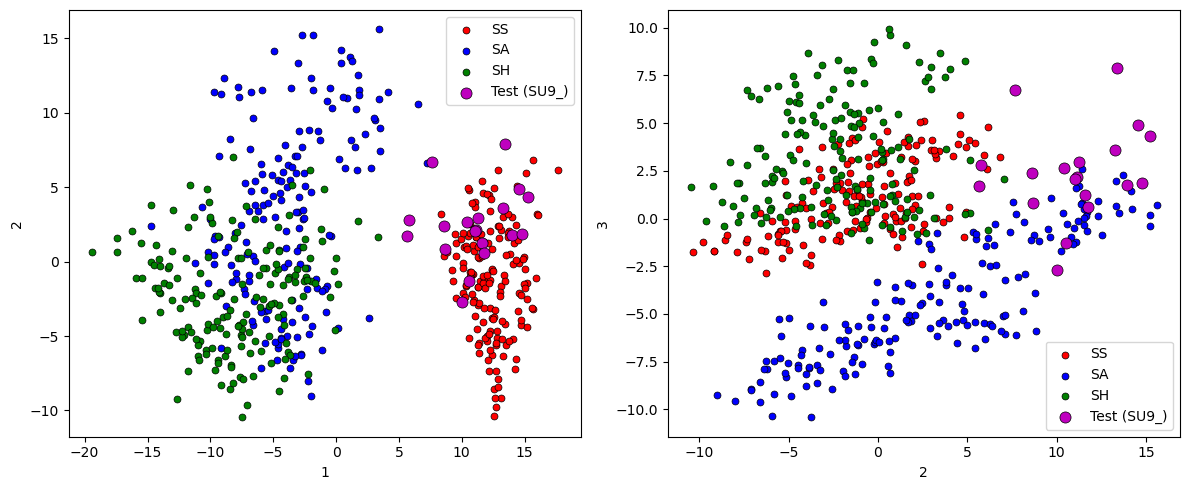

In [83]:
keys = list(dd_test.keys())
for key in keys:
    sp = dd_test.spectra[key]
    Ys_test = sp.y
    U_test = (Ys_test - c) @ As.T
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.scatter(U_SS[:,0], U_SS[:,1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U_SA[:,0], U_SA[:,1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,0], U_SH[:,1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_test[:,0], U_test[:,1], s=64, c='m', edgecolors='k', linewidth=0.5, label=f"Test ({sp.key[:4]})")
    plt.xlabel(str(1))
    plt.ylabel(str(2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
    plt.subplot(1,2,2)
    plt.scatter(U_SS[:,1], U_SS[:,2], s=25, c='r', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U_SA[:,1], U_SA[:,2], s=25, c='b', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,1], U_SH[:,2], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_test[:,0], U_test[:,1], s=64, c='m', edgecolors='k', linewidth=0.5, label=f"Test ({sp.key[:4]})")
    plt.xlabel(str(2))
    plt.ylabel(str(3))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()


In [84]:
keys = list(dd_test.keys())
# cls_names = [key.split("_")[0] for key in keys]
@ipywidgets.interact(key=keys)
def plot_cls(key):
    dd_key = dd_test[key]
    Ys_A = dd_key.y

    # print("1:SS 2:SH 3:SA")

    Z1_A = lfm1.evaluate(Ys_A)
    Z2_A = lfm2.evaluate(Ys_A)
    Z3_A = lfm3.evaluate(Ys_A)
    Y1_A = (1 + (Z1_A - Z3_A) / 2) / 2
    Y2_A = (1 + (Z2_A - Z1_A) / 2) / 2
    Y3_A = (1 + (Z3_A - Z2_A) / 2) / 2
    Y1_A[Y1_A<0] = 0
    Y2_A[Y2_A<0] = 0
    Y3_A[Y3_A<0] = 0
    zz1_A = Y1_A
    zz2_A = Y2_A * np.exp(2j/3 * np.pi)
    zz3_A = Y3_A * np.exp(-2j/3 * np.pi)
    XX_A = np.c_[np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A)] 

    C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
    plt.figure(figsize=(9,5))
    xx, yy = np.meshgrid(np.linspace(-0.8, 0.8, 100), np.linspace(-0.7, 0.7, 100))
    xy = np.c_[xx.ravel(), yy.ravel()]
    zz = lrg.predict(xy)
    zz = zz.reshape(xx.shape)
    plt.imshow(zz, alpha=0.2, cmap=plt.cm.rainbow, extent=(-0.8,0.8,-0.8,0.8), origin="lower")
    
    cs=plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=16, c=C)
    plt.colorbar(cs, ticks=[1,2,3])
    plt.scatter(np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A), s=16, marker='x', c="brown", label="test")
    # plt.scatter(np.real(zz1_B+zz2_B+zz3_B), np.imag(zz1_B+zz2_B+zz3_B), s=16, marker='x', c="green", label="B")
    # plt.scatter(np.real(zz1_C+zz2_C+zz3_C), np.imag(zz1_C+zz2_C+zz3_C), s=16, marker='x', c="magenta", label="C")
    # plt.scatter(np.real(zz1_D+zz2_D+zz3_D), np.imag(zz1_D+zz2_D+zz3_D), s=15, marker='x', c="red", label="D")
    plt.legend()
    plt.text(-0.4,-0.4, "SA")
    plt.text(0.4,-0.4, "SS")
    plt.text(-0.4,0.4, "SH")
    plt.show()
    

interactive(children=(Dropdown(description='key', options=('SU10___21_Test__1_термический_20260703_super_SE__H…

## Проекции обученных классификаторов для тестовых классов.

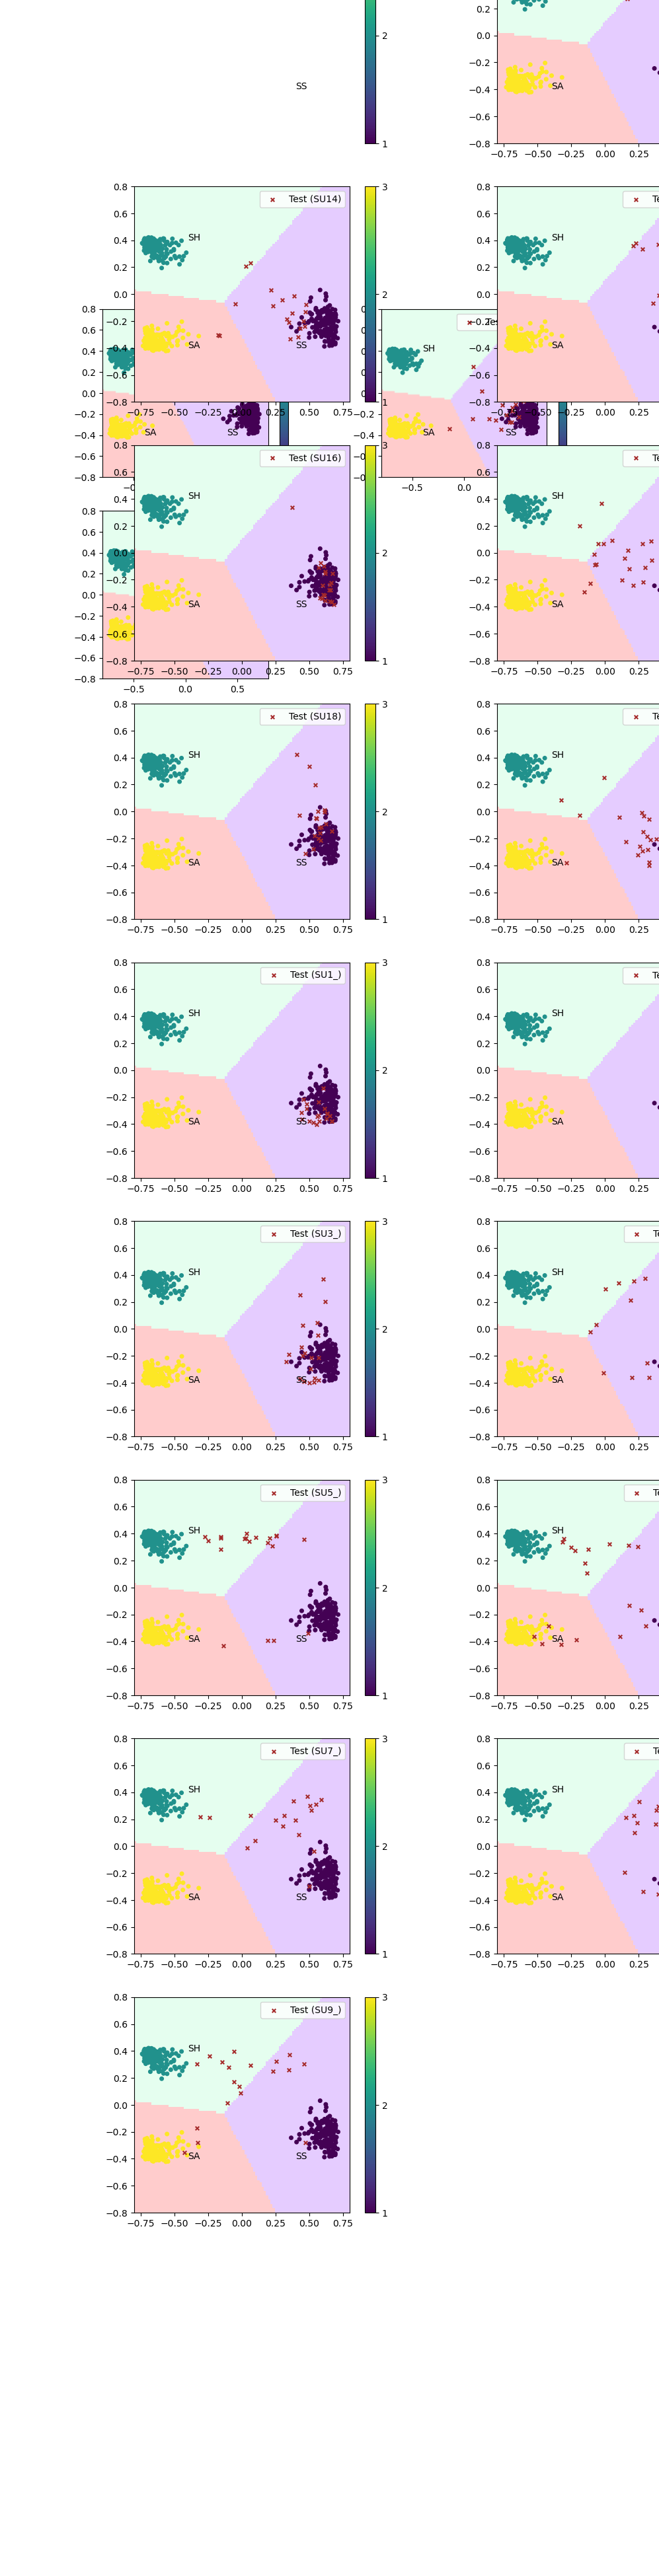

In [85]:
keys = list(dd_test.keys())
N = len(keys)
m = N // 2 + 1
k = 1
for key in keys:
    plt.figure(figsize=(8,6))
    dd_key = dd_test[key]
    Ys_A = dd_key.y

    # print("1:SS 2:SH 3:SA")

    Z1_A = lfm1.evaluate(Ys_A)
    Z2_A = lfm2.evaluate(Ys_A)
    Z3_A = lfm3.evaluate(Ys_A)
    Y1_A = (1 + (Z1_A - Z3_A) / 2) / 2
    Y2_A = (1 + (Z2_A - Z1_A) / 2) / 2
    Y3_A = (1 + (Z3_A - Z2_A) / 2) / 2
    Y1_A[Y1_A<0] = 0
    Y2_A[Y2_A<0] = 0
    Y3_A[Y3_A<0] = 0
    zz1_A = Y1_A
    zz2_A = Y2_A * np.exp(2j/3 * np.pi)
    zz3_A = Y3_A * np.exp(-2j/3 * np.pi)
    XX_A = np.c_[np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A)] 

    C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
    xx, yy = np.meshgrid(np.linspace(-0.8, 0.8, 100), np.linspace(-0.7, 0.7, 100))
    xy = np.c_[xx.ravel(), yy.ravel()]
    zz = lrg.predict(xy)
    zz = zz.reshape(xx.shape)
    plt.imshow(zz, alpha=0.2, cmap=plt.cm.rainbow, extent=(-0.8,0.8,-0.8,0.8), origin="lower")
    
    cs=plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=16, c=C)
    plt.colorbar(cs, ticks=[1,2,3])
    plt.scatter(np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A), s=16, marker='x', c="brown", label=f"Test ({dd_key.key[:4]})")
    # plt.scatter(np.real(zz1_B+zz2_B+zz3_B), np.imag(zz1_B+zz2_B+zz3_B), s=16, marker='x', c="green", label="B")
    # plt.scatter(np.real(zz1_C+zz2_C+zz3_C), np.imag(zz1_C+zz2_C+zz3_C), s=16, marker='x', c="magenta", label="C")
    # plt.scatter(np.real(zz1_D+zz2_D+zz3_D), np.imag(zz1_D+zz2_D+zz3_D), s=15, marker='x', c="red", label="D")
    plt.legend()
    plt.text(-0.4,-0.4, "SA")
    plt.text(0.4,-0.4, "SS")
    plt.text(-0.4,0.4, "SH")
    k += 1
plt.show()
    